# Libraries & Dependencies

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn.datasets as datasets

In [44]:
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use('dark_background')

# Model

- Weights and bias initialization
- Feedforward
- Loss calculation
- Backpropagation
- Fit

In [45]:
# Class for the generic model
class NnModel:

    # Model initialization function
    def __init__(self, x: np.ndarray, y: np.ndarray, hidden_neurons: int=6, output_neurons: int=4):

        np.random.seed(8)
        self.x = x
        self.y = y
        self.hidden_neurons = hidden_neurons
        self.output_neurons = output_neurons
        self.input_neurons = self.x.shape[1]

        # ------------------------- Input layer to hidden layer phase ------------------------- 
        # Generates a random matrix by dividing random numbers by the square root of the number of input neurons (application of Xavier Glorot initialization)
        self.W1 = np.random.randn(self.input_neurons, self.hidden_neurons) / np.sqrt(self.input_neurons)
        # Creates a matrix of zeros with the shape of 1 row and number of columns equal to the number of neurons in the hidden layer
        self.B1 = np.zeros((1, self.hidden_neurons))

        # ------------------------- Hidden layer to output layer phase -------------------------
        # Same process as W1 and B1, but now going from the hidden layer to the output layer
        self.W2 = np.random.randn(self.hidden_neurons, self.output_neurons) / np.sqrt(self.hidden_neurons)
        self.B2 = np.zeros((1, self.output_neurons))
        # Creates a dictionary to organize and group all weights and biases of the neural network
        self.model_dict = {'W1: ': self.W1, 'B1: ': self.B1, 'W2: ': self.W2, 'B2: ': self.B2}
        # Variable that stores the matrix multiplication between matrices X and W1 added to matrix B1
        self.z1 = 0
        # Variable that stores the value of z1 after passing through the activation function
        self.f1 = 0

    def forward(self, x: np.ndarray) -> np.array:
        
        # Linear equation 1 (Z1 = X.W1 + B1)
        self.z1 = x.dot(self.W1) + self.B1
        # Activation function (hyperbolic tangent)
        self.f1 = np.tanh(self.z1)
        # Linear equation 2 (Z2 = F1.W2 + B2)
        z2 = self.f1.dot(self.W2) + self.B2
        # Applies Euler's exponential function to each element of matrix Z2 to store the result
        exp_values = np.exp(z2)
        # Softmax function to calculate probabilities for multiclass classification
        softmax = exp_values / np.sum(exp_values, axis=1, keepdims=True)
        # Returns the probability distribution of each class for the samples
        # Example: [0.05, 0.85, 0.08, 0.02] or [5%, 85%, 8%, 2%].
        return softmax
        
    def loss(self, softmax):
        
        # Variable that accumulates the total error of the entire batch
        total_loss = 0.0
        # Variable that stores the number of rows in the dataset
        batch_size = self.y.shape[0]
        # Loop structure that performs a complete scan across all rows of the dataset
        for i, correct_index in enumerate(self.y):
            # Captures the current row and the position of the ground truth label
            predicted = softmax[i][correct_index]
            # Stores the captured value in the 'predicted' variable and applies the negative logarithm
            log_prob = -np.log(predicted)
            # Error accumulator (sums the result of log_prob at each iteration of the for loop)
            total_loss += log_prob
            
        # Returns the result of total_loss after the loop iteration divided by the total number of rows in the dataset (average)
        return total_loss / batch_size

    def backpropagation(self, softmax: np.ndarray, learning_rate: float) -> None:

        # Creates a copy of the Softmax matrix
        delta2 = np.copy(softmax)
        # Goes to the ground truth position of the dataset and decrements the value in the delta2 matrix (copy of the softmax matrix) by 1
        delta2[range(self.x.shape[0]), self.y] -= 1
        # Calculates the gradient for the weights of layer 2
        dW2 = (self.f1.T).dot(delta2)
        # Sums all columns of the delta2 matrix and transforms it into a matrix of 1 row by the number of classes in the dataset
        dB2 = np.sum(delta2, axis=0, keepdims=True)
        # Creates a new matrix with the same shape as the hidden layer containing the error of each neuron in the layer
        delta1 = delta2.dot(self.W2.T)*(1-np.power(np.tanh(self.z1), 2))
        # The same process as dW2 and dB2, but now going from the hidden layer back to the input layer
        dW1 = (self.x.T).dot(delta1)
        dB1 = np.sum(delta1, axis=0, keepdims=True)
        # Updates the weights and biases through gradient descent
        self.W1 += - learning_rate*dW1
        self.W2 += - learning_rate*dW2
        self.B1 += - learning_rate*dB1
        self.B2 += - learning_rate*dB2

    def fit(self, epochs: int, lr: float):

        # Loop structure that serves as the epoch loop
        for epoch in range(epochs):
            # Stores the result of the data passing the features (dataset columns) through the neural network
            outputs = self.forward(self.x)
            # Stores the loss result by passing 'outputs' into the loss function
            loss = self.loss(outputs)
            # Calls the backpropagation function passing the result (outputs) and the learning rate (lr)
            self.backpropagation(outputs, lr)
            # Stores the highest-scoring class (the one with the highest value in the analyzed row)
            prediction = np.argmax(outputs, axis=1)
            # Stores the total number of hits by comparing the prediction with the ground truth
            correct = (prediction == self.y).sum()
            # Calculates accuracy by summing the total hits and dividing by the total number of rows in the dataset (average)
            accuracy = correct/self.y.shape[0]
            # Configuration to print training progress (epoch, accuracy, and loss)
            if int((epoch+1) % (epochs/10)) == 0:
                print(f'Epoch: [{epoch+1} / {epochs}] Accuracy: {accuracy:.3f} Loss: {loss.item():.5f}')
                
        # Returns a vector with the predicted classes in the dataset
        return prediction

## Hyperparameter Configuration

In [46]:
hidden_neurons = 6
output_neurons = 4
learning_rate = 0.001
epochs = 10

## Dataset Initialization

- **n_samples=400**: number of rows (samples) in the dataset
- **n_features=4**: number of columns (features) in the dataset
- **centers=4**: total number of clusters (groups) to generate
- **random_state=50**: random seed set to generate reproducible data
- **cluster_std=0.7**: controls how spread out the points are around each cluster center
- **shuffle=True**: shuffles the order of the samples in the dataset 

In [47]:
x, y = datasets.make_blobs(n_samples=400, n_features=4, centers=4, random_state=50, cluster_std=0.7, shuffle=True)

## Dataset Overview

In [48]:
print(f'{x.shape = }, {y.shape = }')

x.shape = (400, 4), y.shape = (400,)


In [49]:
pd.DataFrame({'x1': x[:,0], 'x2': x[:,1], 'x3': x[:,2], 'x4': x[:,3], 'y': y})

,x1,x2,x3,x4,y
0,-2.034437,10.930016,-0.539607,6.050010,1
1,-2.397382,10.889794,-2.137117,4.995249,1
2,-0.511551,-5.316168,-3.586786,-2.548178,0
3,-6.144439,10.542898,8.093967,2.140017,3
4,-5.683314,9.465638,7.867266,1.111539,3
...,...,...,...,...,...
395,-1.548464,9.690473,-1.891290,5.162159,1
396,-0.203622,-6.541505,-3.922612,-2.184915,0
397,-3.883962,10.400494,-1.069381,6.244382,1
398,5.366978,-3.780123,-2.085610,-2.342713,2


In [50]:
unique = np.unique(y, return_counts=True)
for label, qt_label in zip(unique[0], unique[1]):
    print(f'Group: {label}\t Counts: {qt_label}')

Group: 0	 Counts: 100
Group: 1	 Counts: 100
Group: 2	 Counts: 100
Group: 3	 Counts: 100


## 3D Data Visualization

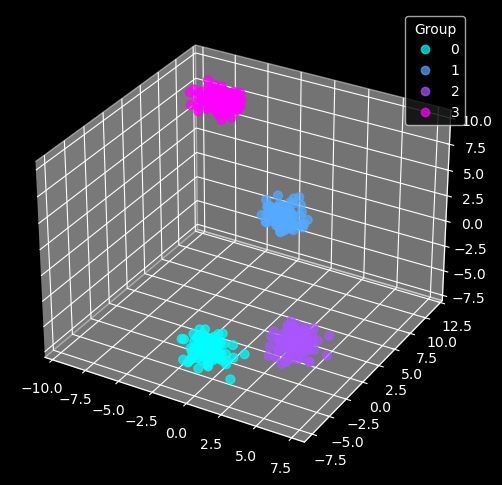

In [51]:
ax = plt.axes(projection = '3d')
ax.scatter3D(x[:,0], x[:,1], x[:,2], s=40, c=y, cmap='cool', alpha=0.7)
ax.legend(*scatter.legend_elements(), title='Group')

## Initializing and Fitting the Model

In [52]:
model = NnModel(x, y, hidden_neurons=hidden_neurons, output_neurons=output_neurons)
result = model.fit(epochs, learning_rate)

Epoch: [1 / 10] Accuracy: 0.297 Loss: 1.51331
Epoch: [2 / 10] Accuracy: 0.743 Loss: 0.87848
Epoch: [3 / 10] Accuracy: 1.000 Loss: 0.63989
Epoch: [4 / 10] Accuracy: 1.000 Loss: 0.48955
Epoch: [5 / 10] Accuracy: 1.000 Loss: 0.38747
Epoch: [6 / 10] Accuracy: 1.000 Loss: 0.31640
Epoch: [7 / 10] Accuracy: 1.000 Loss: 0.26593
Epoch: [8 / 10] Accuracy: 1.000 Loss: 0.22888
Epoch: [9 / 10] Accuracy: 1.000 Loss: 0.20067
Epoch: [10 / 10] Accuracy: 1.000 Loss: 0.17849


## 3D Visualization After Model Training

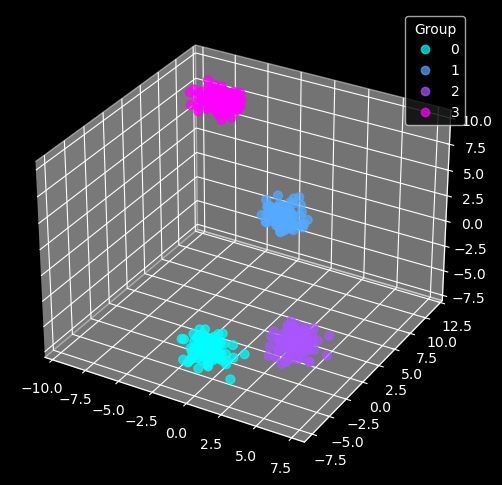

In [53]:
ax = plt.axes(projection = '3d')
ax.scatter3D(x[:,0], x[:,1], x[:,2], s=40, c=result, cmap='cool', alpha=0.7)
ax.legend(*scatter.legend_elements(), title='Group')